In [ ]:
!pip install -q pandas numpy scikit-learn xgboost openpyxl matplotlib

In [ ]:
import pandas as pd

url = "https://raw.githubusercontent.com/SohamDas04/Dynamic-crop-price-prediction-using-time-series-data/main/Agmarknet_Price_Report%20%281%29.csv"

market_df = pd.read_csv(url)

print("Dataset shape:", market_df.shape)
print("\nColumns:")
print(market_df.columns.tolist())

print("\nDate range:")
print(market_df["Price Date"].min(), "to", market_df["Price Date"].max())

print("\nUnique dates:", market_df["Price Date"].nunique())

display(market_df.head())

Dataset shape: (5651, 9)

Columns:
['District Name', 'Market Name', 'Commodity', 'Variety', 'Grade', 'Min Price (Rs./Quintal)', 'Max Price (Rs./Quintal)', 'Modal Price (Rs./Quintal)', 'Price Date']

Date range:
01-Apr-06 to 31-Oct-23

Unique dates: 5648


,District Name,Market Name,Commodity,Variety,Grade,Min Price (Rs./Quintal),Max Price (Rs./Quintal),Modal Price (Rs./Quintal),Price Date
0,Varanasi,Varanasi(Grain),Wheat,Other,FAQ,660,700,685,01-Jan-03
1,Varanasi,Varanasi(Grain),Wheat,Other,FAQ,660,700,685,02-Jan-03
2,Varanasi,Varanasi(Grain),Wheat,Other,FAQ,660,700,685,03-Jan-03
3,Varanasi,Varanasi(Grain),Wheat,Other,FAQ,675,750,700,04-Jan-03
4,Varanasi,Varanasi(Grain),Wheat,Other,FAQ,680,750,700,06-Jan-03


In [ ]:
# Make a fresh copy
price_df = market_df.copy()

# Clean column names
price_df.columns = (
    price_df.columns
    .str.strip()
    .str.replace(" ", "_")
    .str.replace("(", "", regex=False)
    .str.replace(")", "", regex=False)
    .str.replace("/", "", regex=False)
    .str.replace(".", "", regex=False)
)

# Show the actual cleaned column names
print("Cleaned columns:")
print(price_df.columns.tolist())

# Rename columns using the actual names
price_df = price_df.rename(columns={
    "Price_Date": "Date",
    "Market_Name": "Market",
    "Min_Price_RsQuintal": "Min_Price",
    "Max_Price_RsQuintal": "Max_Price",
    "Modal_Price_RsQuintal": "Modal_Price"
})

# Convert date
price_df["Date"] = pd.to_datetime(
    price_df["Date"],
    format="%d-%b-%y",
    errors="coerce"
)

# Convert prices to numeric
for col in ["Min_Price", "Max_Price", "Modal_Price"]:
    price_df[col] = pd.to_numeric(
        price_df[col],
        errors="coerce"
    )

# Remove missing records
price_df = price_df.dropna(
    subset=["Date", "Commodity", "Market", "Modal_Price"]
)

# Sort chronologically
price_df = price_df.sort_values("Date").reset_index(drop=True)

print("\nCleaned shape:", price_df.shape)

print("\nDate range:")
print(price_df["Date"].min(), "to", price_df["Date"].max())

print("\nTop commodities:")
print(price_df["Commodity"].value_counts().head(15))

print("\nTop markets:")
print(price_df["Market"].value_counts().head(15))

Cleaned columns:
['District_Name', 'Market_Name', 'Commodity', 'Variety', 'Grade', 'Min_Price_RsQuintal', 'Max_Price_RsQuintal', 'Modal_Price_RsQuintal', 'Price_Date']

Cleaned shape: (5651, 9)

Date range:
2003-01-01 00:00:00 to 2023-12-30 00:00:00

Top commodities:
Commodity
Wheat    5651
Name: count, dtype: int64

Top markets:
Market
Varanasi(Grain)    5651
Name: count, dtype: int64


In [ ]:
# Create the time-series dataset
ts_df = price_df[["Date", "Modal_Price"]].copy()

# If multiple records exist for the same date, take the average
ts_df = (
    ts_df.groupby("Date", as_index=False)["Modal_Price"]
    .mean()
    .sort_values("Date")
    .reset_index(drop=True)
)

# Lag features
ts_df["lag_1"] = ts_df["Modal_Price"].shift(1)
ts_df["lag_7"] = ts_df["Modal_Price"].shift(7)
ts_df["lag_14"] = ts_df["Modal_Price"].shift(14)
ts_df["lag_30"] = ts_df["Modal_Price"].shift(30)

# Rolling averages
ts_df["rolling_7"] = ts_df["Modal_Price"].shift(1).rolling(7).mean()
ts_df["rolling_14"] = ts_df["Modal_Price"].shift(1).rolling(14).mean()
ts_df["rolling_30"] = ts_df["Modal_Price"].shift(1).rolling(30).mean()

# Calendar features
ts_df["day"] = ts_df["Date"].dt.day
ts_df["month"] = ts_df["Date"].dt.month
ts_df["year"] = ts_df["Date"].dt.year
ts_df["day_of_year"] = ts_df["Date"].dt.dayofyear

# Remove rows created by lagging
ts_df = ts_df.dropna().reset_index(drop=True)

print("Time-series shape:", ts_df.shape)

print("\nFeatures:")
print(ts_df.columns.tolist())

display(ts_df.head())

Time-series shape: (5618, 13)

Features:
['Date', 'Modal_Price', 'lag_1', 'lag_7', 'lag_14', 'lag_30', 'rolling_7', 'rolling_14', 'rolling_30', 'day', 'month', 'year', 'day_of_year']


,Date,Modal_Price,lag_1,lag_7,lag_14,lag_30,rolling_7,rolling_14,rolling_30,day,month,year,day_of_year
0,2003-02-13,780.0,780.0,760.0,740.0,685.0,775.714286,758.928571,734.333333,13,2,2003,44
1,2003-02-14,785.0,780.0,760.0,740.0,685.0,778.571429,761.785714,737.500000,14,2,2003,45
2,2003-02-15,785.0,785.0,785.0,750.0,685.0,782.142857,765.000000,740.833333,15,2,2003,46
3,2003-02-17,780.0,785.0,785.0,740.0,700.0,782.142857,767.500000,744.166667,17,2,2003,48
4,2003-02-18,775.0,780.0,780.0,745.0,700.0,781.428571,770.357143,746.833333,18,2,2003,49


In [ ]:
# Features and target
features = [
    "lag_1",
    "lag_7",
    "lag_14",
    "lag_30",
    "rolling_7",
    "rolling_14",
    "rolling_30",
    "day",
    "month",
    "year",
    "day_of_year"
]

X = ts_df[features]
y = ts_df["Modal_Price"]

# Chronological 80/20 split
split_index = int(len(ts_df) * 0.80)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining period:")
print(ts_df["Date"].iloc[0], "to", ts_df["Date"].iloc[split_index - 1])

print("\nTesting period:")
print(ts_df["Date"].iloc[split_index], "to", ts_df["Date"].iloc[-1])

Training samples: 4494
Testing samples: 1124

Training period:
2003-02-13 00:00:00 to 2019-11-27 00:00:00

Testing period:
2019-11-28 00:00:00 to 2023-12-30 00:00:00


In [ ]:
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Create XGBoost model
market_model = XGBRegressor(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42
)

# Train
market_model.fit(X_train, y_train)

# Predict
y_pred = market_model.predict(X_test)

# Evaluation
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("Market Price Forecasting Results")
print("--------------------------------")
print(f"MAE  : {mae:.2f}")
print(f"RMSE : {rmse:.2f}")
print(f"R²   : {r2:.4f}")

Market Price Forecasting Results
--------------------------------
MAE  : 193.57
RMSE : 315.16
R²   : -0.3848


In [ ]:
# Create improved forecasting dataset
improved_df = ts_df.copy()

# Additional short-term lag features
improved_df["lag_2"] = improved_df["Modal_Price"].shift(2)
improved_df["lag_3"] = improved_df["Modal_Price"].shift(3)

# Price-change target
improved_df["price_ratio"] = (
    improved_df["Modal_Price"] / improved_df["lag_1"]
)

# Remove missing values
improved_df = improved_df.dropna().reset_index(drop=True)

# Remove infinite values from price_ratio
improved_df = improved_df.replace([np.inf, -np.inf], np.nan).dropna().reset_index(drop=True)

# Features
improved_features = [
    "lag_1",
    "lag_2",
    "lag_3",
    "lag_7",
    "lag_14",
    "lag_30",
    "rolling_7",
    "rolling_14",
    "rolling_30",
    "month",
    "day_of_year"
]

X_imp = improved_df[improved_features]
y_imp = improved_df["price_ratio"]

# Chronological 80/20 split
split = int(len(improved_df) * 0.80)

X_train_imp = X_imp.iloc[:split]
X_test_imp = X_imp.iloc[split:]

y_train_imp = y_imp.iloc[:split]
y_test_imp = y_imp.iloc[split:]

print("Training samples:", len(X_train_imp))
print("Testing samples:", len(X_test_imp))

Training samples: 4489
Testing samples: 1123


In [ ]:
# Train improved XGBoost model
improved_model = XGBRegressor(
    n_estimators=800,
    learning_rate=0.03,
    max_depth=5,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42
)

improved_model.fit(X_train_imp, y_train_imp)

# Predict price ratio
ratio_pred = improved_model.predict(X_test_imp)

# Convert predicted ratio back to actual price
actual_previous_price = improved_df["lag_1"].iloc[split:].values
actual_prices = improved_df["Modal_Price"].iloc[split:].values

predicted_prices = actual_previous_price * ratio_pred

# Evaluation
mae = mean_absolute_error(actual_prices, predicted_prices)
rmse = np.sqrt(mean_squared_error(actual_prices, predicted_prices))
r2 = r2_score(actual_prices, predicted_prices)

print("Improved Market Price Forecasting Results")
print("-----------------------------------------")
print(f"MAE  : {mae:.2f}")
print(f"RMSE : {rmse:.2f}")
print(f"R²   : {r2:.4f}")

Improved Market Price Forecasting Results
-----------------------------------------
MAE  : 223.30
RMSE : 364.60
R²   : -0.8517


Yearly average wheat price:


,Modal_Price
Date,
2003,731.691176
2004,737.138554
2005,801.146953
2006,973.163194
2007,1056.936027
2008,1084.414894
2009,1111.160410
2010,1163.902724
2011,1195.986842


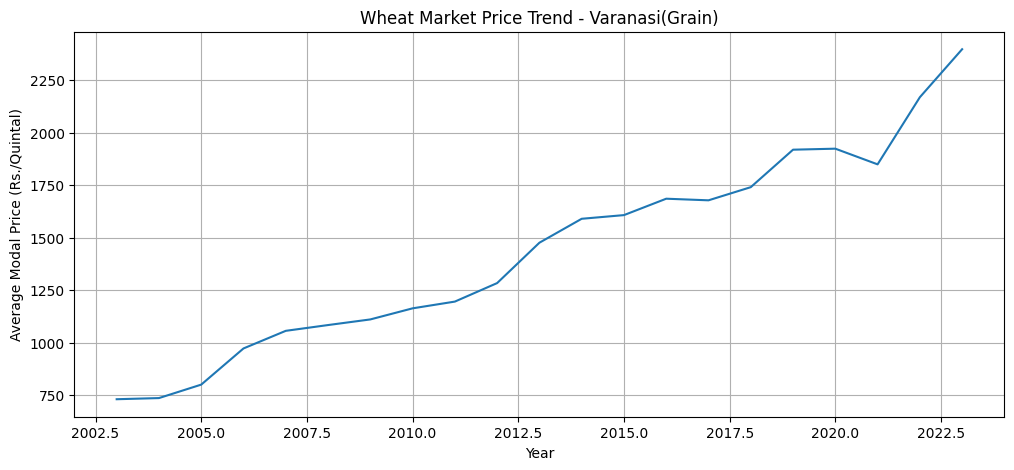

In [ ]:
import matplotlib.pyplot as plt

# Yearly average price
yearly_price = (
    price_df.groupby(price_df["Date"].dt.year)["Modal_Price"]
    .mean()
)

print("Yearly average wheat price:")
display(yearly_price)

# Plot price trend
plt.figure(figsize=(12, 5))
plt.plot(yearly_price.index, yearly_price.values)
plt.xlabel("Year")
plt.ylabel("Average Modal Price (Rs./Quintal)")
plt.title("Wheat Market Price Trend - Varanasi(Grain)")
plt.grid(True)
plt.show()

In [ ]:
from sklearn.linear_model import LinearRegression
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Copy time series
model_df = ts_df.copy()

# Create numeric time index
model_df["time_index"] = np.arange(len(model_df))

# Fit linear trend using training data only
split = int(len(model_df) * 0.80)

trend_model = LinearRegression()
trend_model.fit(
    model_df[["time_index"]].iloc[:split],
    model_df["Modal_Price"].iloc[:split]
)

# Estimate trend for every observation
model_df["trend"] = trend_model.predict(
    model_df[["time_index"]]
)

# Calculate residual from long-term trend
model_df["residual"] = (
    model_df["Modal_Price"] - model_df["trend"]
)

# Residual lag features
model_df["res_lag_1"] = model_df["residual"].shift(1)
model_df["res_lag_7"] = model_df["residual"].shift(7)
model_df["res_lag_14"] = model_df["residual"].shift(14)
model_df["res_lag_30"] = model_df["residual"].shift(30)

model_df["res_rolling_7"] = (
    model_df["residual"].shift(1).rolling(7).mean()
)

model_df["res_rolling_14"] = (
    model_df["residual"].shift(1).rolling(14).mean()
)

model_df = model_df.dropna().reset_index(drop=True)

# Features for residual prediction
trend_features = [
    "res_lag_1",
    "res_lag_7",
    "res_lag_14",
    "res_lag_30",
    "res_rolling_7",
    "res_rolling_14",
    "month",
    "day_of_year"
]

X = model_df[trend_features]
y = model_df["residual"]

# Chronological split
split = int(len(model_df) * 0.80)

X_train = X.iloc[:split]
X_test = X.iloc[split:]

y_train = y.iloc[:split]
y_test = y.iloc[split:]

# Train XGBoost on residuals
trend_xgb = XGBRegressor(
    n_estimators=500,
    learning_rate=0.03,
    max_depth=5,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42
)

trend_xgb.fit(X_train, y_train)

# Predict residual
residual_pred = trend_xgb.predict(X_test)

# Add predicted residual back to trend
test_trend = model_df["trend"].iloc[split:].values
predicted_prices = test_trend + residual_pred

actual_prices = model_df["Modal_Price"].iloc[split:].values

# Evaluation
mae = mean_absolute_error(actual_prices, predicted_prices)
rmse = np.sqrt(mean_squared_error(actual_prices, predicted_prices))
r2 = r2_score(actual_prices, predicted_prices)

print("Trend + XGBoost Market Price Forecasting")
print("----------------------------------------")
print(f"MAE  : {mae:.2f}")
print(f"RMSE : {rmse:.2f}")
print(f"R²   : {r2:.4f}")

Trend + XGBoost Market Price Forecasting
----------------------------------------
MAE  : 55.89
RMSE : 111.97
R²   : 0.8261


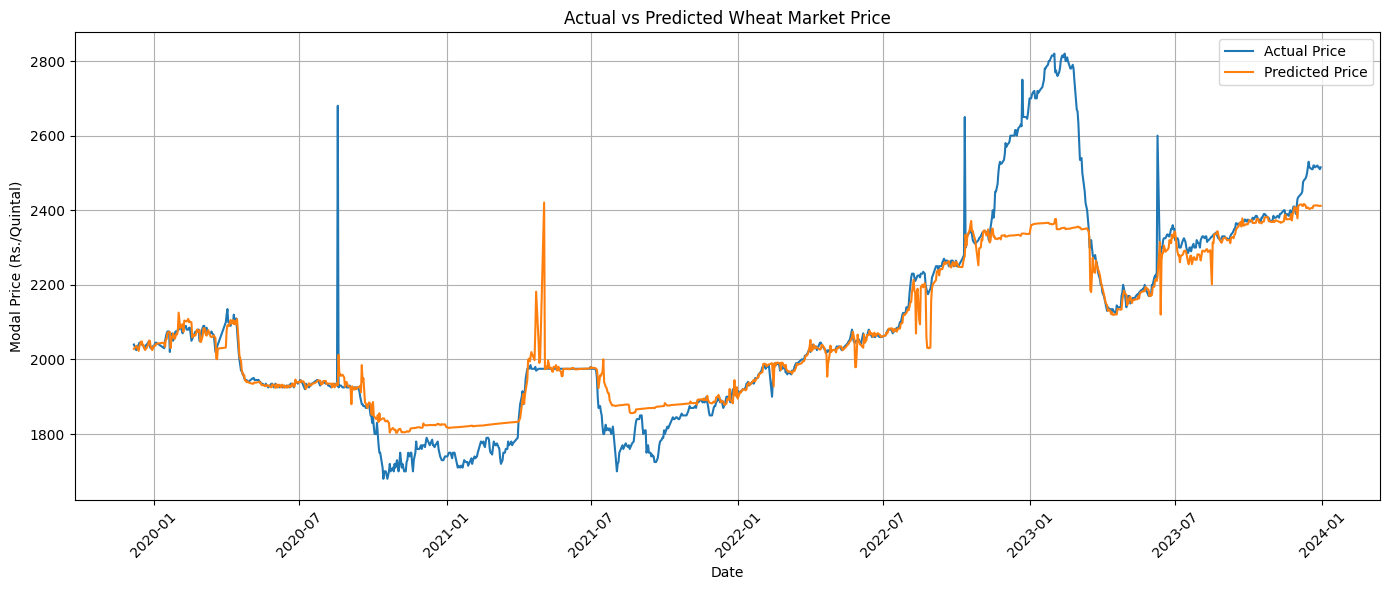

In [ ]:
import matplotlib.pyplot as plt

# Test dates
test_dates = model_df["Date"].iloc[split:]

plt.figure(figsize=(14, 6))

plt.plot(
    test_dates,
    actual_prices,
    label="Actual Price"
)

plt.plot(
    test_dates,
    predicted_prices,
    label="Predicted Price"
)

plt.xlabel("Date")
plt.ylabel("Modal Price (Rs./Quintal)")
plt.title("Actual vs Predicted Wheat Market Price")
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
from google.colab import drive
import os
import joblib

# Mount Google Drive
drive.mount("/content/drive")

# Create/check MyDrive path
save_dir = "/content/drive/MyDrive"

print("Drive mounted:", os.path.exists(save_dir))

# Save XGBoost residual model
joblib.dump(
    trend_xgb,
    f"{save_dir}/market_price_xgboost_model.pkl"
)

# Save trend model
joblib.dump(
    trend_model,
    f"{save_dir}/market_price_trend_model.pkl"
)

# Save feature names
joblib.dump(
    trend_features,
    f"{save_dir}/market_price_feature_names.pkl"
)

# Save model information
market_model_info = {
    "commodity": "Wheat",
    "market": "Varanasi(Grain)",
    "target": "Modal_Price",
    "unit": "Rs./Quintal",
    "date_range": "2003-2023",
    "MAE": mae,
    "RMSE": rmse,
    "R2": r2
}

joblib.dump(
    market_model_info,
    f"{save_dir}/market_price_model_info.pkl"
)

print("\nMarket Price Forecasting models saved successfully!")

print("\nSaved files:")
print("✓ market_price_xgboost_model.pkl")
print("✓ market_price_trend_model.pkl")
print("✓ market_price_feature_names.pkl")
print("✓ market_price_model_info.pkl")

Mounted at /content/drive
Drive mounted: True

Market Price Forecasting models saved successfully!

Saved files:
✓ market_price_xgboost_model.pkl
✓ market_price_trend_model.pkl
✓ market_price_feature_names.pkl
✓ market_price_model_info.pkl
